# 04 — Multimodal AI: Visual, Acoustic & Systems Latency Audit
Inspects real golden fixtures across **Vision** (`128x128 RGB CHW`) and **Audio VAD** (`16 kHz mono PCM -> [100, 2] log_rms + zcr`), evaluates model Macro-F1 vs. CPU latency, and visualizes why media demuxing dominates end-to-end video inference latency.

In [1]:
import base64
import io
import json
import wave
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

cwd = Path.cwd().resolve()
ROOT_DIR = next(p for p in [cwd, *cwd.parents] if (p / 'feature_contract.json').exists())
ARTIFACTS_DIR = ROOT_DIR / 'artifacts'

contract = json.loads((ROOT_DIR / 'feature_contract.json').read_text())
bench_df = pd.DataFrame(json.loads((ARTIFACTS_DIR / 'benchmark_summary.json').read_text()))
golden = json.loads((ARTIFACTS_DIR / 'golden_fixtures.json').read_text())

print(f"Schema Version: {golden['schema_version']} | Schema Hash: {golden['schema_hash']}")
print(f"Golden Fixtures: {len(golden['ekyc_cases'])} eKYC + {len(golden['unboxing_cases'])} Unboxing + {len(golden['audio_cases'])} Audio = {len(golden['ekyc_cases']) + len(golden['unboxing_cases']) + len(golden['audio_cases'])} total")
bench_df

Schema Version: v1.0.0 | Schema Hash: 559a7112982a
Golden Fixtures: 20 eKYC + 20 Unboxing + 20 Audio = 60 total


,model,macro_f1,cpu_p50_ms,size_mb
0,eKYC Vision (2D-CNN),0.6436,0.123,0.092
1,Unboxing Vision (CNN),0.9208,0.116,0.092
2,Audio VAD (1D-CNN),1.0000,0.019,0.012


Saved /home/gun/work/github.com/gunawanwijaya/apprentice/04-multimodal-ai/artifacts/multimodal_samples_preview.png


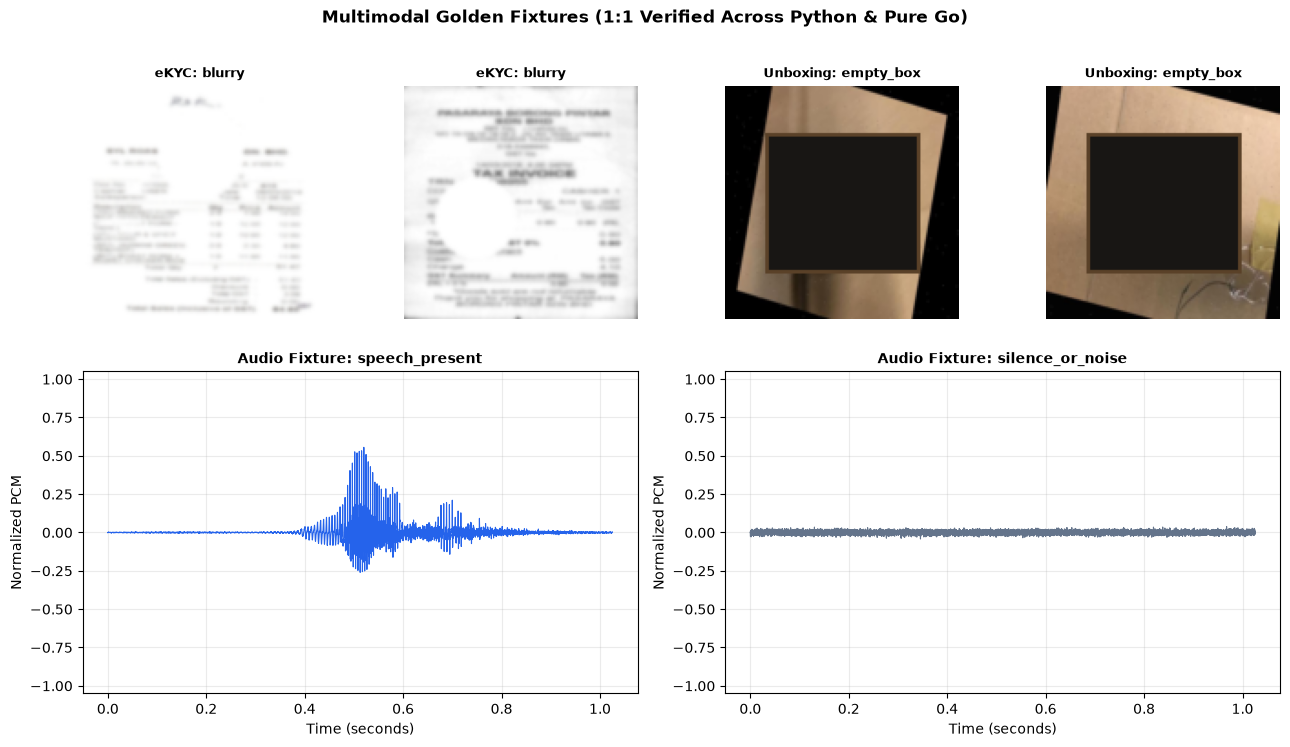

In [2]:
def decode_b64_png(b64_str: str) -> Image.Image:
    return Image.open(io.BytesIO(base64.b64decode(b64_str))).convert('RGB')

def decode_b64_wav(b64_str: str) -> np.ndarray:
    with wave.open(io.BytesIO(base64.b64decode(b64_str)), 'rb') as wf:
        pcm = np.frombuffer(wf.readframes(wf.getnframes()), dtype='<i2')
    return pcm.astype(np.float32) / 32768.0

fig = plt.figure(figsize=(13, 7.5))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.05])

# Top row: 2 eKYC fixtures + 2 Unboxing fixtures
visual_samples = [
    ('eKYC', golden['ekyc_cases'][0]),
    ('eKYC', golden['ekyc_cases'][1]),
    ('Unboxing', golden['unboxing_cases'][0]),
    ('Unboxing', golden['unboxing_cases'][1]),
]
for idx, (domain, case) in enumerate(visual_samples):
    ax = fig.add_subplot(gs[0, idx])
    ax.imshow(decode_b64_png(case['png_b64']))
    ax.set_title(f"{domain}: {case['expected_label']}", fontsize=9.5, fontweight='bold')
    ax.axis('off')

# Bottom row: Speech vs Silence/Noise waveforms from golden WAV fixtures
speech_case = next((c for c in golden['audio_cases'] if c['expected_label'] == 'speech_present'), golden['audio_cases'][0])
noise_case = next((c for c in golden['audio_cases'] if c['expected_label'] == 'silence_or_noise'), golden['audio_cases'][-1])

sr = contract['audio']['sample_rate']
for col_span, title, case, color in [
    (slice(0, 2), f"Audio Fixture: {speech_case['expected_label']}", speech_case, '#2563eb'),
    (slice(2, 4), f"Audio Fixture: {noise_case['expected_label']}", noise_case, '#64748b'),
]:
    ax = fig.add_subplot(gs[1, col_span])
    wav = decode_b64_wav(case['wav_b64'])
    t_axis = np.arange(len(wav)) / sr
    ax.plot(t_axis, wav, color=color, lw=0.8)
    ax.set_ylim(-1.05, 1.05)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Normalized PCM')
    ax.grid(alpha=0.25)

plt.suptitle('Multimodal Golden Fixtures (1:1 Verified Across Python & Pure Go)', fontsize=12, fontweight='bold', y=0.99)
plt.tight_layout()
preview_path = ARTIFACTS_DIR / 'multimodal_samples_preview.png'
plt.savefig(preview_path, dpi=150)
print(f'Saved {preview_path}')
plt.show()

Saved /home/gun/work/github.com/gunawanwijaya/apprentice/04-multimodal-ai/artifacts/multimodal_benchmark_summary.png


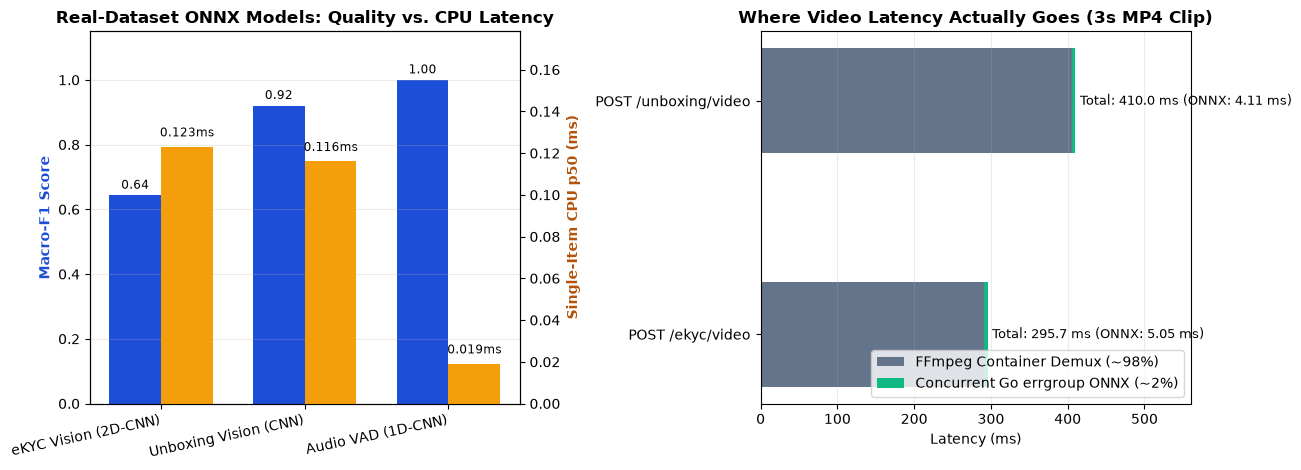

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: Macro-F1 & CPU p50 Latency per ONNX Model
models = bench_df['model'].tolist()
f1s = bench_df['macro_f1'].tolist()
latencies = bench_df['cpu_p50_ms'].tolist()
x = np.arange(len(models))
width = 0.36

ax1 = axes[0]
bars1 = ax1.bar(x - width / 2, f1s, width, label='Macro-F1', color='#1d4ed8')
ax1.set_ylim(0, 1.15)
ax1.set_ylabel('Macro-F1 Score', color='#1d4ed8', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=12, ha='right')
ax1.grid(axis='y', alpha=0.25)

ax1_b = ax1.twinx()
bars2 = ax1_b.bar(x + width / 2, latencies, width, label='CPU p50 (ms)', color='#f59e0b')
ax1_b.set_ylim(0, max(latencies) * 1.45)
ax1_b.set_ylabel('Single-Item CPU p50 (ms)', color='#b45309', fontweight='bold')

for b in bars1:
    ax1.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f'{b.get_height():.2f}', ha='center', fontsize=8.5)
for b in bars2:
    ax1_b.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f'{b.get_height():.3f}ms', ha='center', fontsize=8.5)
ax1.set_title('Real-Dataset ONNX Models: Quality vs. CPU Latency', fontweight='bold')

# Right: End-to-End Video Endpoint Latency Breakdown (Measured on Go Server)
endpoints = ['POST /ekyc/video', 'POST /unboxing/video']
demux_ms = [290.6, 405.9]
onnx_ms = [5.05, 4.11]

ax2 = axes[1]
ax2.barh(endpoints, demux_ms, label='FFmpeg Container Demux (~98%)', color='#64748b', height=0.45)
ax2.barh(endpoints, onnx_ms, left=demux_ms, label='Concurrent Go errgroup ONNX (~2%)', color='#10b981', height=0.45)
for i, (d, inf) in enumerate(zip(demux_ms, onnx_ms)):
    ax2.text(d + inf + 6, i, f'Total: {d + inf:.1f} ms (ONNX: {inf:.2f} ms)', va='center', fontsize=9)
ax2.set_xlim(0, 560)
ax2.set_xlabel('Latency (ms)')
ax2.set_title('Where Video Latency Actually Goes (3s MP4 Clip)', fontweight='bold')
ax2.legend(loc='lower right')
ax2.grid(axis='x', alpha=0.25)

plt.tight_layout()
summary_path = ARTIFACTS_DIR / 'multimodal_benchmark_summary.png'
plt.savefig(summary_path, dpi=150)
print(f'Saved {summary_path}')
plt.show()